# 1.2 Análisis de los registros de mantenimiento

Actividad **1.2**: verificar cómo se relacionan `PdM_maint` y `PdM_failures`, y responder:

1. ¿Qué registros de mantenimiento son consecuencia de una falla?
2. ¿Qué riesgo implica usarlos como variable de entrada?

Las métricas de la §3 se calculan solo sobre el periodo de entrenamiento.

In [1]:
import sys, warnings
from pathlib import Path

ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import average_precision_score, roc_auc_score

from src.data import load_all, assign_split, classify_maint, H
from src.plots import set_style, savefig

set_style()
pd.set_option("display.precision", 3)
HOUR = np.timedelta64(1, "h")

d = load_all()
tel, mnt, fail = d["telemetry"], d["maint"], d["failures"]

## 1. Empatar reemplazos con fallas

Cada reemplazo se clasifica con `src.data.classify_maint`:

| tipo | definición |
|---|---|
| **falla** | Reemplaza el componente que falló, en la misma máquina y hora. |
| **oportunista** | Reemplaza otro componente en la misma visita de una falla. |
| **programado** | Reemplazo en una máquina y hora sin falla. |

In [2]:
mt = classify_maint(mnt, fail)
mt["periodo"] = np.where(mt["datetime"] < "2015-01-01", "2014", assign_split(mt["datetime"]).fillna("2016").values)
tab = pd.crosstab(mt["tipo"], mt["periodo"], margins=True, margins_name="total")
tab[["2014", "train", "val", "test", "2016", "total"]]

periodo,2014,train,val,test,2016,total
tipo,,,,,,
falla,0,504,118,121,0,743
oportunista,0,190,44,45,0,279
programado,400,1222,314,321,7,2264
total,400,1916,476,487,7,3286


In [3]:
# Dirección inversa: ¿cada falla tiene su reemplazo?
fm = fail.merge(mt[mt["tipo"] == "falla"][["machineID", "datetime", "comp"]],
                left_on=["machineID", "datetime", "failure"], right_on=["machineID", "datetime", "comp"],
                how="left", indicator=True)
print(fm["_merge"].map({"both": "falla con reemplazo simultáneo", "left_only": "falla SIN reemplazo"}).value_counts())
print("Fecha de las fallas sin reemplazo:", fm.loc[fm["_merge"] == "left_only", "datetime"].unique())

_merge
falla con reemplazo simultáneo    743
falla SIN reemplazo                18
Name: count, dtype: int64
Fecha de las fallas sin reemplazo: <DatetimeArray>
['2015-01-02 03:00:00']
Length: 1, dtype: datetime64[ns]


## 2. Calendario de visitas

Fallas y reemplazos de 2015 ocurren en una rejilla de visitas **cada 15 días (360 h)**, con un desfase propio por máquina. Se verifica aquí porque una de las variables candidatas de la §3 depende de él.

In [4]:
O = pd.Timestamp("2015-01-01 06:00")
CYCLE = 360
grid_phase = lambda ts: ((ts - O) / HOUR) % CYCLE

m15 = mt[mt["datetime"] >= "2015-01-01"]
phase = grid_phase(m15["datetime"]).groupby(m15["machineID"]).agg(["nunique", "first"])
assert (phase["nunique"] == 1).all()
PHASE = phase["first"]
on_grid = lambda df: grid_phase(df["datetime"]).values == df["machineID"].map(PHASE).values
print(f"Reemplazos 2015–16 en la rejilla de su máquina: {on_grid(m15).mean():.1%}")
print(f"Fallas en la rejilla de su máquina: {on_grid(fail).sum()}/{len(fail)}")

Reemplazos 2015–16 en la rejilla de su máquina: 100.0%
Fallas en la rejilla de su máquina: 743/761


## 3. Cuantificación del riesgo de fuga

Para cada hora de **entrenamiento** se define *y*(*t*) = 1 si hay falla en (*t*, *t* + 24 h]. Después se mide cuánto separa *y* cada variable candidata derivada del mantenimiento, por sí sola y sin modelo.

| variable | cómo se calcula | ¿legítima? |
|---|---|---|
| `h_desde_reemplazo` | horas desde el último reemplazo, registros ≤ *t* | sí (causal) |
| `h_desde_falla` | horas desde el último reemplazo tipo *falla*, ≤ *t* | sí (causal) |
| `reemplazos_dia` | n.º de reemplazos en el día calendario de *t* | **no**: ve hasta 6 h al futuro |
| `reemplazo_prox_24h` | ¿hay un reemplazo en (*t*, *t* + 24]? | **no**: es el futuro |
| `falla_prox_24h_via_maint` | ¿hay un reemplazo tipo *falla* en (*t*, *t* + 24]? | **no**: es la etiqueta |
| `h_hasta_visita` | horas hasta la siguiente visita programada | artefacto de calendario |

In [5]:
g = tel[["machineID", "datetime"]].copy()
g["split"] = assign_split(g["datetime"]).values

def asof(left, right, direction, exact=True):
    r = right.rename(columns={"datetime": "_t"}).sort_values("_t")
    out = pd.merge_asof(left.reset_index().sort_values("datetime"), r, left_on="datetime", right_on="_t",
                        by="machineID", direction=direction, allow_exact_matches=exact)
    return out.set_index("index").sort_index()["_t"]

fh = fail[["machineID", "datetime"]].drop_duplicates()
g["y"] = ((asof(g, fh, "forward", exact=False) - g["datetime"]) <= pd.Timedelta(hours=H)).astype(int)

rep = mt[["machineID", "datetime"]].drop_duplicates()
rep_f = mt[mt["tipo"] == "falla"][["machineID", "datetime"]].drop_duplicates()
BIG = 24 * 365.0

g["h_desde_reemplazo"] = ((g["datetime"] - asof(g, rep, "backward")) / HOUR).fillna(BIG)
g["h_desde_falla"] = ((g["datetime"] - asof(g, rep_f, "backward")) / HOUR).fillna(BIG)
daily = mt.assign(fecha=mt["datetime"].dt.normalize()).groupby(["machineID", "fecha"]).size().rename("reemplazos_dia")
g["fecha"] = g["datetime"].dt.normalize()
g = g.join(daily, on=["machineID", "fecha"]).drop(columns="fecha")
g["reemplazos_dia"] = g["reemplazos_dia"].fillna(0)
g["reemplazo_prox_24h"] = ((asof(g, rep, "forward", exact=False) - g["datetime"]) <= pd.Timedelta(hours=H)).astype(int)
g["falla_prox_24h_via_maint"] = ((asof(g, rep_f, "forward", exact=False) - g["datetime"]) <= pd.Timedelta(hours=H)).astype(int)
g["h_hasta_visita"] = (g["machineID"].map(PHASE) - (g["datetime"] - O) / HOUR) % CYCLE
g.loc[g["h_hasta_visita"] == 0, "h_hasta_visita"] = CYCLE

tr = g[g["split"] == "train"]
# signo: +1 si valores altos indican falla, −1 si valores bajos la indican
FEATS = {"h_desde_reemplazo": 1, "h_desde_falla": 1, "reemplazos_dia": 1,
         "reemplazo_prox_24h": 1, "falla_prox_24h_via_maint": 1, "h_hasta_visita": -1}
leak = pd.DataFrame({f: (average_precision_score(tr["y"], s * tr[f]), roc_auc_score(tr["y"], s * tr[f]))
                     for f, s in FEATS.items()}, index=["PR-AUC", "ROC-AUC"]).T
leak["legítima"] = ["sí", "sí", "no (ve 6 h futuro)", "no (futuro)", "no (es la etiqueta)", "artefacto"]
print(f"Tasa base (PR-AUC de un clasificador aleatorio) en train: {tr['y'].mean():.4f}")
leak.sort_values("PR-AUC", ascending=False)

Tasa base (PR-AUC de un clasificador aleatorio) en train: 0.0202


,PR-AUC,ROC-AUC,legítima
falla_prox_24h_via_maint,0.972,0.986,no (es la etiqueta)
reemplazo_prox_24h,0.326,0.967,no (futuro)
h_hasta_visita,0.289,0.962,artefacto
h_desde_reemplazo,0.068,0.857,sí
reemplazos_dia,0.039,0.597,no (ve 6 h futuro)
h_desde_falla,0.026,0.599,sí


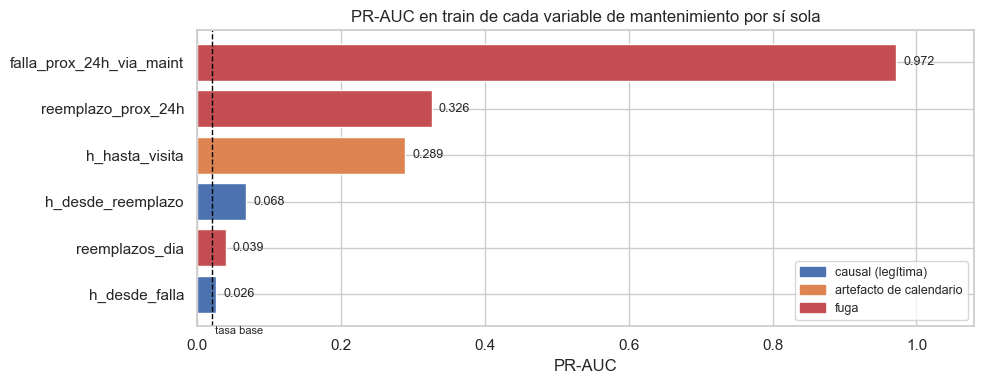

In [6]:
fig, ax = plt.subplots(figsize=(10, 4))
lk = leak.sort_values("PR-AUC")
colors = ["#c44e52" if v.startswith("no") else ("#dd8452" if v == "artefacto" else "#4c72b0") for v in lk["legítima"]]
ax.barh(lk.index, lk["PR-AUC"], color=colors)
ax.axvline(tr["y"].mean(), color="black", ls="--", lw=1)
ax.text(tr["y"].mean(), -0.9, " tasa base", fontsize=8, va="bottom")
for i, v in enumerate(lk["PR-AUC"]):
    ax.text(v + 0.01, i, f"{v:.3f}", va="center", fontsize=9)
ax.set(title="PR-AUC en train de cada variable de mantenimiento por sí sola", xlabel="PR-AUC", xlim=(0, 1.08))
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in ["#4c72b0", "#dd8452", "#c44e52"]]
ax.legend(handles, ["causal (legítima)", "artefacto de calendario", "fuga"], loc="lower right", fontsize=9)
plt.tight_layout()
savefig(fig, "04_maint_leakage")

## Respuestas

**¿Qué registros de mantenimiento son consecuencia de una falla?**

De los 3 286 registros:

- **743 son tipo falla.** Corresponden exactamente a una falla: misma máquina, hora y componente. `PdM_failures` está contenido en `PdM_maint`, salvo 18 fallas del 2015-01-02 a las 03:00 que no tienen registro.
- **279 son oportunistas.** Otros componentes reemplazados en la misma visita de una falla; comparten su marca de tiempo.
- **2 264 son programados.** Incluyen los 400 de 2014, que solo inicializan la edad de cada componente.

**¿Qué riesgo implica usarlos como variable de entrada?**

1. **Fuga directa.** Cualquier variable que mire hacia adelante desde *t* reconstruye la etiqueta. Los registros tipo falla *son* la etiqueta: por sí solos dan PR-AUC = 0.97 en train, contra una tasa base de 0.02.
2. **Fuga por agregación.** Agregar por día calendario hace que las horas 00:00–05:00 vean el registro de las 06:00, que es futuro.
3. **Artefacto de calendario.** Las fallas solo se registran en día de visita, cada 15 días. Una variable causal como "horas hasta la siguiente visita" da ROC-AUC = 0.96 sin mirar ningún sensor. Las "horas desde el último reemplazo" que pide 1.4 codifican en parte esa misma fase. No es fuga en sentido estricto, porque la información está disponible en *t*, pero no se trasladaría a una planta real.

**Decisiones para 1.3 y 1.4**
- La etiqueta se construye solo desde `PdM_failures`.
- Las variables de mantenimiento usan solo registros con `datetime ≤ t`. No se usan agregaciones por día calendario.